# **Heartbeat classification**
**Authors:** Gustav Freitag, Ivaylo Staykov | **Date:** Feburary/March 2026

## Project Overview
The aim of this project is to develop and test an AI assistant that can accurately classify single heartbeats into five different diagnostic categories using data from the MIT-BIH Arrhythmia database. In medical diagnosis, it is generally considered more serious to miss a life threatening case than to have a false alarm. Hence, the project focuses on reducing the false negatives of severe cases.

## Key Objectives
* **Model Comparison:** Evaluate and compare the performance of a Multilayer Perceptron (MLP) and a 1D Convolutional Neural Network (1D, CNN).
* **Metric Focus:** Achieve high Sensitivity (Recall) on rare, dangerous classes, and maximize the F1-Score for the "ventricular" class.
* **Interpretability:** Generate saliency maps highlighting which parts of the heartbeat waveform most influence the model's decisions.

## Dataset Overview and Clinical Context

This project utilizes the **MIT-BIH Arrhythmia Dataset**, originally hosted on PhysioNet and pre-processed for machine learning on Kaggle.

* **Original Source:** [PhysioNet MIT-BIH Arrhythmia Database](https://physionet.org/content/mitdb/1.0.0/)
* **Cleaned Dataset:** [Kaggle ECG Heartbeat Categorization Dataset](https://www.kaggle.com/datasets/shayanfazeli/heartbeat/data)

### Dataset Specifications
* **Total Samples:** 109,446 heartbeats
* **Number of Categories:** 5
* **Sampling Frequency:** 125Hz (187 time steps per heartbeat)
* **Format:** 1D arrays representing the ECG signal amplitude over time.

### Diagnostic Categories
The dataset classifies individual heartbeats into five distinct groups based on the Association for the Advancement of Medical Instrumentation (AAMI) standard:

* **Class 0 (`N`): Non-ectopic beats** - These are normal, healthy heartbeats.
* **Class 1 (`S`): Supraventricular ectopic beats** - Abnormal beats originating in the upper chambers (atria) of the heart. While they can cause palpitations, they are generally less immediately dangerous.
* **Class 2 (`V`): Ventricular ectopic beats** - Abnormal beats originating in the lower pumping chambers (ventricles). **This is our primary class of interest.**
* **Class 3 (`F`): Fusion beats** - Occur when a normal electrical impulse and a ventricular ectopic impulse happen simultaneously, creating a hybrid heartbeat.
* **Class 4 (`Q`): Unknown beats** - Unclassifiable beats, heavily paced beats, or artifacts.

### Clinical Focus: The Danger of Ventricular Arrhythmias
Not all arrhythmias carry the same risk. While normal beats (`N`) make up the vast majority of the data, our AI must excel at identifying **Ventricular ectopic beats (`V`)**.

When ectopic beats originate in the ventricles, the heart can struggle to pump blood effectively to the rest of the body. Frequent or consecutive ventricular ectopic beats can escalate into Ventricular Tachycardia (VT) or Ventricular Fibrillation (VF), which are life-threatening medical emergencies that can lead to sudden cardiac arrest.

Because missing a dangerous condition is far worse than triggering a false alarm in the medical field, **this project prioritizes high Sensitivity (Recall) and a maximized F1-Score specifically for the Ventricular (`V`) class.**

## 1. Imports


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os

import kagglehub

import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score

## 2. Data Loading and Preparation
The dataset used is the ECG Heartbeat Categorization Dataset from Kaggle. We will download this directly into the Colab environment using the Kaggle API.

In [ ]:
path = kagglehub.dataset_download("shayanfazeli/heartbeat")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'heartbeat' dataset.
Path to dataset files: /kaggle/input/heartbeat


In [ ]:
# the dataset has no headers, so we specify header=None
# the first 187 columns are the ECG signal, and the 188th column is the label
train_path = os.path.join(path, "mitbih_train.csv")
test_path = os.path.join(path, "mitbih_test.csv")

train_df = pd.read_csv(train_path, header=None)
test_df = pd.read_csv(test_path, header=None)

print(f"Training data shape: {train_df.shape}")
print(f"Testing data shape:  {test_df.shape}")

# preview first few rows
train_df.head()

Training data shape: (87554, 188)
Testing data shape:  (21892, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Exploratory Data Analysis (EDA)

Before building our neural networks, we need to understand the distribution of our data. Since we are dealing with medical data, it is very common to have a severe class imbalance. Most patients have normal heartbeats, while the dangerous arrhythmias we want to detect are relatively rare.

Let's visualize the distribution of our 5 diagnostic categories.

sample counts per class:
187
N (Normal)              72471
Q (Unknown)              6431
V (Ventricular)          5788
S (Supraventricular)     2223
F (Fusion)                641


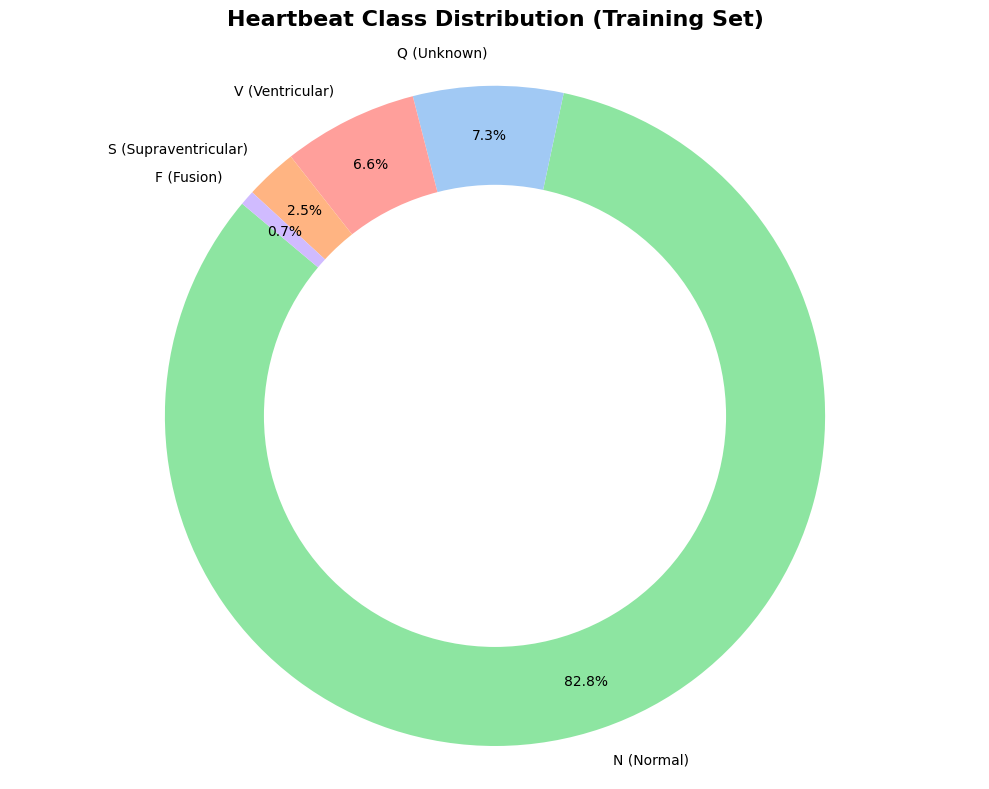

In [ ]:
labels = train_df.iloc[:, -1].astype(int)

# map numerical labels to medical names
class_names = {
    0: 'N (Normal)',
    1: 'S (Supraventricular)',
    2: 'V (Ventricular)',
    3: 'F (Fusion)',
    4: 'Q (Unknown)'
}

# count occurrences
label_counts = labels.map(class_names).value_counts()

print("sample counts per class:")
print(label_counts.to_string())

# pie chart
plt.figure(figsize=(10, 8))
colors = ['#8DE5A1', '#A1C9F4', '#FF9F9B', '#FFB482', '#D0BBFF']

plt.pie(label_counts,
        labels=label_counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        pctdistance=0.85)

# Draw a white circle in the center to turn the pie chart into a Donut Chart
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)


plt.title('Heartbeat Class Distribution (Training Set)', fontsize=16, fontweight='bold', pad=20)
plt.axis('equal')
plt.tight_layout()
plt.savefig("class_distribution_donut.png", dpi=300)
plt.show()

### Visualizing the ECG Signals

To understand what our models will learn, let's look at the actual shape of the heartbeats. The dataset provides these signals as 1D arrays of 187 time steps, where the amplitude has already been normalized between 0 and 1.

Below, we sample one heartbeat from each of the five diagnostic categories. Notice how the shape of the Ventricular beat differs from the Normal beat.

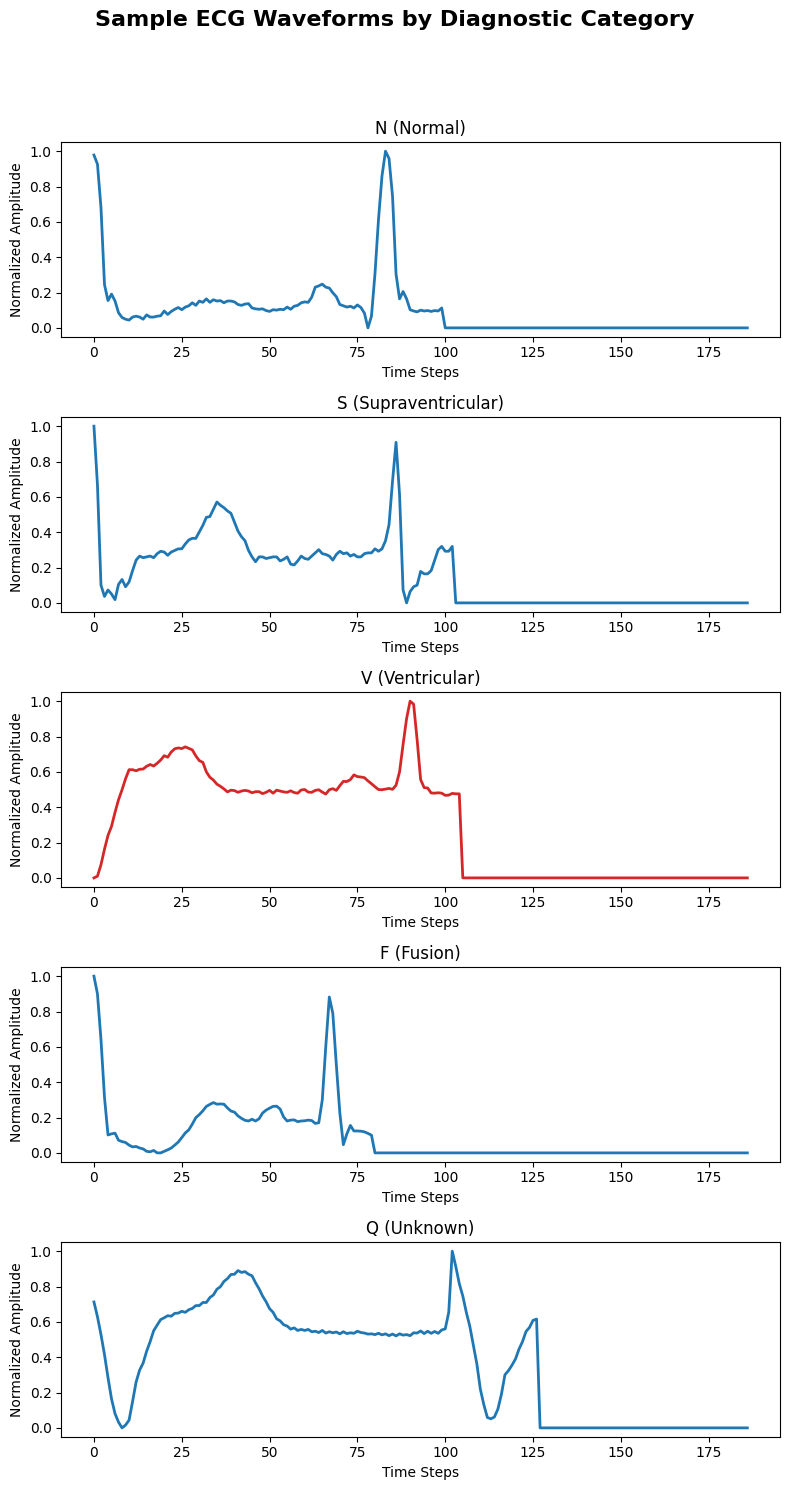

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(8, 15))
fig.suptitle('Sample ECG Waveforms by Diagnostic Category', fontsize=16, fontweight='bold', y=1.02)

for i in range(5):
    class_data = train_df[train_df.iloc[:, 187] == i]
    sample = class_data.iloc[0, :187]

    line_color = '#d62728' if i == 2 else '#1f77b4' # red for ventricular (class 2), blue for the rest

    axes[i].plot(sample.values, color=line_color, linewidth=2)
    axes[i].set_title(class_names[i], fontsize=12)

    axes[i].set_xlabel('Time Steps')
    axes[i].set_ylabel('Normalized Amplitude')

plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # adjusted rect for subtitle
plt.show()

## 4. Handling Class Imbalance

As observed in the EDA, the MIT-BIH dataset is severely imbalanced, with the 'Normal' class dominating the dataset. Because our primary objective is to maximize Sensitivity (Recall) for the dangerous 'Ventricular' class, we must address this imbalance.

We considered several approaches:
1. **Undersampling:** Discarding majority class data. *Rejected because deep learning models require large amounts of data to generalize well; discarding real ECG variance is detrimental.*
2. **Oversampling/SMOTE:** Generating synthetic minority samples. *Rejected because generating synthetic medical time-series data can introduce unnatural artifacts that the model might incorrectly memorize.*
3. **Cost-Sensitive Learning (Class Weights):** Applying class-specific weights to the Loss Function.

**Selected Approach: Cost-Sensitive Learning**
We will keep the dataset unaltered to preserve the true clinical data distribution. Instead, we will calculate class weights based on the inverse frequency of each class. We will pass these weights into our PyTorch `CrossEntropyLoss` function. This forces the neural network to incur a much higher penalty for misclassifying a rare, dangerous arrhythmia compared to misclassifying a normal heartbeat, directly optimizing our model for high Recall on minority classes.

## 5. Data Preprocessing for PyTorch

To train our models in PyTorch, we need to convert our Pandas DataFrames into PyTorch **Tensors**, wrap them in a **Dataset**, and load them using a **DataLoader** to handle batching.

Additionally, to implement our Cost-Sensitive Learning strategy, we will calculate the **Class Weights** based on the inverse frequency of each heartbeat category in the training set. These weights will later be passed into our loss function.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight

# separate features X and labels y
X_train = train_df.iloc[:, :-1].values
y_train = train_df.iloc[:, -1].values.astype(int)

X_test = test_df.iloc[:, :-1].values
y_test = test_df.iloc[:, -1].values.astype(int)

# 'balanced' formula: n_samples / (n_classes * np.bincount(y))
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

print("Calculated Class Weights:")
for i, weight in enumerate(class_weights_array):
    print(f"Class {i} ({class_names[i]}): {weight:.4f}")

Calculated Class Weights:
Class 0 (N (Normal)): 0.2416
Class 1 (S (Supraventricular)): 7.8771
Class 2 (V (Ventricular)): 3.0254
Class 3 (F (Fusion)): 27.3179
Class 4 (Q (Unknown)): 2.7229


### Adjusting Weights for Clinical Severity
While standard inverse-frequency weighting balances the dataset mathematically, it ignores clinical context. For instance, the 'Fusion' class (Class 3) receives a massive weight simply because it is the rarest in the dataset, not because it is the most dangerous.

Following clinical guidelines and project objectives, our primary goal is to maximize Recall and F1-score for the **Ventricular (Class 2)** beats due to their severe risk to patient life. To force the model to prioritize this specific class, we apply a **Clinical Severity Multiplier** to artificially boost the weight of Class 2 in the PyTorch loss function, ensuring the penalty for missing a Ventricular beat outweighs the purely statistical weights of less dangerous arrhythmias.

In [ ]:
CLINICAL_BOOST_V = 5.0
class_weights_array[2] = class_weights_array[2] * CLINICAL_BOOST_V

print("Calculated Class Weights:")
for i, weight in enumerate(class_weights_array):
      print(f"Class {i} ({class_names[i]}): {weight:.4f}")

class_weights = torch.tensor(class_weights_array, dtype=torch.float32)

Calculated Class Weights:
Class 0 (N (Normal)): 0.2416
Class 1 (S (Supraventricular)): 7.8771
Class 2 (V (Ventricular)): 15.1268
Class 3 (F (Fusion)): 27.3179
Class 4 (Q (Unknown)): 2.7229


### Creating Tensors, Datasets and Dataloaders

In [ ]:
# PyTorch expects features as float32 and labels as long (int64) for classification
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

BATCH_SIZE = 64

# We shuffle the training data so the model doesn't learn the order of the rows
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Created Train DataLoader with {len(train_loader)} batches of size {BATCH_SIZE}.")
print(f"Created Test DataLoader with {len(test_loader)} batches of size {BATCH_SIZE}.")

Created Train DataLoader with 1369 batches of size 64.
Created Test DataLoader with 343 batches of size 64.


## 6. Model Architecture: Multi-Layer Perceptron (MLP)

To establish a strong baseline for heartbeat classification, we first implement a Multi-Layer Perceptron (MLP). While MLPs do not inherently capture spatial or temporal hierarchies like CNNs, they are highly effective at learning complex, non-linear representations from flattened data arrays.

**Architecture Details:**
* **Input Layer:** 187 neurons (corresponding to the 187 time-steps of the ECG signal).
* **Hidden Layers:** Three fully connected (dense) layers with decreasing dimensionality (128 -> 64 -> 32 neurons) to compress the feature space and extract the most salient patterns.
* **Activation:** Rectified Linear Unit (ReLU) functions introduce non-linearity, allowing the model to learn complex decision boundaries.
* **Regularization:** Dropout layers (p=0.2) are applied after each hidden layer to randomly deactivate neurons during training, preventing overfitting.
* **Output Layer:** 5 neurons corresponding to our diagnostic categories. We output raw logits, as the PyTorch `CrossEntropyLoss` function internally applies the Softmax activation.

In [ ]:
class HeartbeatMLP(nn.Module):
    def __init__(self, input_size=187, num_classes=5):
        super(HeartbeatMLP, self).__init__()

        self.fc1 = nn.Linear(input_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 32)
        self.fc4 = nn.Linear(32, num_classes)   # Output Layer

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2) # 20% probability of dropping a neuron

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.relu(self.fc3(x))
        x = self.dropout(x)

        x = self.fc4(x)
        return x

mlp_model = HeartbeatMLP()
print(mlp_model)

HeartbeatMLP(
  (fc1): Linear(in_features=187, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (fc4): Linear(in_features=32, out_features=5, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)


## 7. Model Training Setup: Loss Function and Optimizer

To train our network, we must define how it measures its own performance and how it updates its parameters to improve.

* **Loss Function:** We use `CrossEntropyLoss`, the standard for multi-class classification in PyTorch. Crucially, we pass our pre-calculated `class_weights` into this function. This integrates our Cost-Sensitive Learning strategy, applying a much heavier penalty when the model misclassifies our clinically dangerous target class (Ventricular).
* **Optimizer:** We utilize the Adam (Adaptive Moment Estimation) optimizer. Adam dynamically adjusts the learning rate for each parameter during training, which generally leads to faster and more stable convergence compared to standard Stochastic Gradient Descent (SGD).
* **Hardware Acceleration:** Deep learning models train significantly faster on a GPU. We include a device check to automatically utilize NVIDIA GPUs (CUDA) or Apple Silicon GPUs (MPS) if available in the Colab environment, falling back to the CPU otherwise.

In [ ]:
# Colab offers free GPUs. Runtime -> Change runtime type -> T4 GPU to enable it.
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using NVIDIA GPU (CUDA)")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using Apple Silicon GPU (MPS)")
else:
    device = torch.device("cpu")
    print("Using CPU. (Consider switching to a GPU runtime in Colab for faster training!)")

mlp_model = mlp_model.to(device)
class_weights = class_weights.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(mlp_model.parameters(), lr=0.001)

print("\nTraining setup complete. Ready to build the training loop.")

Using NVIDIA GPU (CUDA)

Training setup complete. Ready to build the training loop.


## 8. Model Training

In PyTorch, the training process is defined manually via a loop. For each "Epoch" (a full pass through the entire training dataset), the following core steps are executed:
1. **Zero Gradients:** Clearing old gradients from the previous step so they do not accumulate.
2. **Forward Pass:** Feeding the batch of ECG signals through the network to get predictions.
3. **Loss Calculation:** Comparing the predictions to the true labels using our cost-sensitive `CrossEntropyLoss`.
4. **Backward Pass (Backpropagation):** Calculating the gradients (the direction and magnitude of the error) for every weight in the network.
5. **Optimizer Step:** Updating the network's weights to minimize the loss.

To ensure our model is actually achieving our primary objective, we also evaluate it on the testing set at the end of each epoch, specifically tracking the **F1-Score of the Ventricular class (Class 2)**.

In [ ]:
EPOCHS = 10

history_train_loss = []
history_val_f1_class2 = []


print("Starting training...\n")

for epoch in range(EPOCHS):
    # TRAINING PHASE
    mlp_model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        # move batch data to the GPU/CPU
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()

        outputs = mlp_model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()
        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)
    history_train_loss.append(avg_train_loss)


    # EVALUATION PHASE
    mlp_model.eval()
    mlp_all_preds = []
    mlp_all_targets = []

    # torch.no_grad() speeds up computation and saves memory since we don't need gradients for testing
    with torch.no_grad():
        for X_test_batch, y_test_batch in test_loader:
            X_test_batch, y_test_batch = X_test_batch.to(device), y_test_batch.to(device)

            test_outputs = mlp_model(X_test_batch)

            # The outputs are raw logits. We take the index of the highest value as the predicted class.
            _, predicted_classes = torch.max(test_outputs, 1)

            mlp_all_preds.extend(predicted_classes.cpu().numpy())
            mlp_all_targets.extend(y_test_batch.cpu().numpy())

    f1_scores = f1_score(mlp_all_targets, mlp_all_preds, average=None, zero_division=0)

    v_class_f1 = f1_scores[2]
    history_val_f1_class2.append(v_class_f1)

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | Train Loss: {avg_train_loss:.4f} | Val F1 (Ventricular): {v_class_f1:.4f}")

print("\nTraining complete!")

Starting training...

Epoch [01/10] | Train Loss: 0.7589 | Val F1 (Ventricular): 0.3764
Epoch [02/10] | Train Loss: 0.4988 | Val F1 (Ventricular): 0.3324
Epoch [03/10] | Train Loss: 0.4246 | Val F1 (Ventricular): 0.3527
Epoch [04/10] | Train Loss: 0.3840 | Val F1 (Ventricular): 0.4379
Epoch [05/10] | Train Loss: 0.3598 | Val F1 (Ventricular): 0.4997
Epoch [06/10] | Train Loss: 0.3350 | Val F1 (Ventricular): 0.5517
Epoch [07/10] | Train Loss: 0.3248 | Val F1 (Ventricular): 0.5039
Epoch [08/10] | Train Loss: 0.3122 | Val F1 (Ventricular): 0.5877
Epoch [09/10] | Train Loss: 0.3019 | Val F1 (Ventricular): 0.6250
Epoch [10/10] | Train Loss: 0.2918 | Val F1 (Ventricular): 0.6196

Training complete!


## 9. MLP Evaluation and Diagnostics

After training the baseline Multi-Layer Perceptron, we must evaluate its performance on the unseen test set. Because our dataset is highly imbalanced, overall accuracy is a misleading metric. Instead, we rely on the **Classification Report** (to view Precision, Recall, and F1-Score per class) and the **Confusion Matrix** (to visualize the exact misclassifications).

By analyzing the Confusion Matrix, we can determine if our Cost-Sensitive Learning strategy successfully forced the model to prioritize the detection of Ventricular beats (Class 2), and whether it came at the cost of too many false positives.

Classification Report (MLP Baseline):
-------------------------------------------------------
                      precision    recall  f1-score   support

          N (Normal)       0.99      0.78      0.87     18118
S (Supraventricular)       0.33      0.74      0.46       556
     V (Ventricular)       0.46      0.96      0.62      1448
          F (Fusion)       0.12      0.85      0.21       162
         Q (Unknown)       0.70      0.97      0.81      1608

            accuracy                           0.80     21892
           macro avg       0.52      0.86      0.59     21892
        weighted avg       0.91      0.80      0.84     21892

-------------------------------------------------------


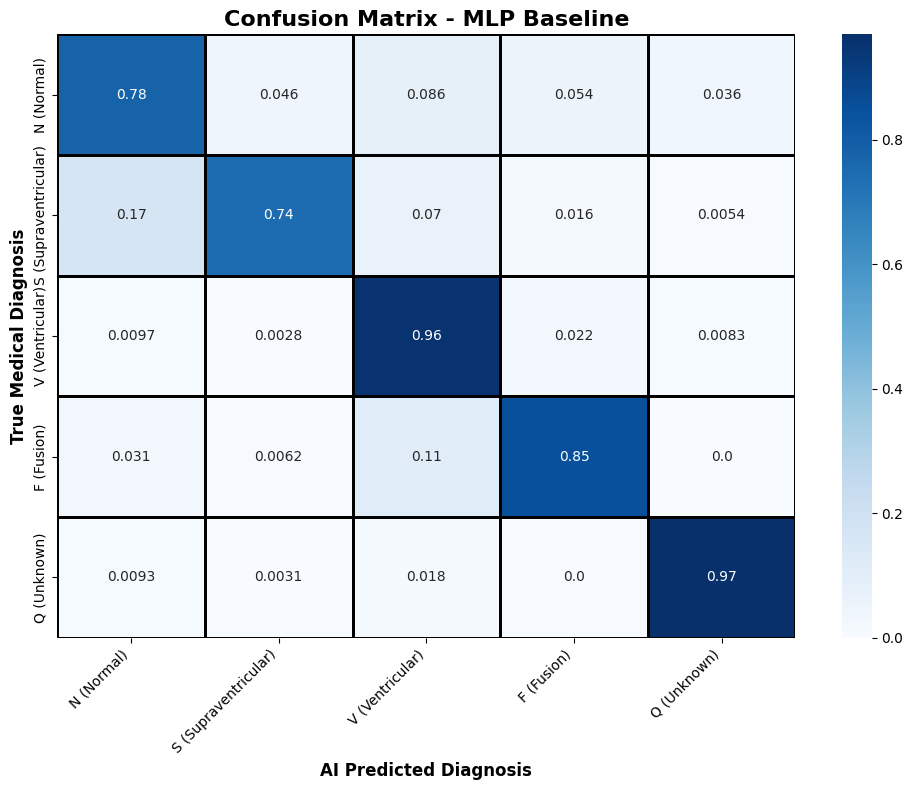

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# classification report
print("Classification Report (MLP Baseline):")
print("-" * 55)
# target_names lets us see the actual medical labels instead of just 0-4
print(classification_report(mlp_all_targets, mlp_all_preds, target_names=list(class_names.values()), zero_division=0))
print("-" * 55)

# confusion matrix
cm = confusion_matrix(mlp_all_targets, mlp_all_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2', cmap='Blues',
            xticklabels=list(class_names.values()),
            yticklabels=list(class_names.values()),
            linewidths=1, linecolor='black')

plt.title('Confusion Matrix - MLP Baseline', fontsize=16, fontweight='bold')
plt.ylabel('True Medical Diagnosis', fontsize=12, fontweight='bold')
plt.xlabel('AI Predicted Diagnosis', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("mlp_confusion_matrix.png", dpi=300)
plt.show()

## 10. MLP Baseline Analysis and Conclusion

The classification report reveals that our Cost-Sensitive Learning strategy was highly effective at achieving our primary clinical objective, though it introduced a clear trade-off:

* **High Sensitivity (Recall) Achieved:** The model achieved a remarkable **0.96 Recall** on the dangerous Ventricular class. It successfully identified 96% of the life-threatening arrhythmias, proving that the clinical weight multiplier effectively forced the network to prioritize this class.
* **Low Precision (False Positives):** The Precision for the Ventricular class sits at **0.46**. Because the penalty for missing a Ventricular beat is so high, the model became overly sensitive, classifying many Normal beats as Ventricular (false alarms).
* **F1-Score Impact:** The resulting F1-Score of **0.62** reflects this imbalance. While a high recall is strictly preferred in medical diagnostics to prevent patient mortality, a precision of 0.46 could lead to "alarm fatigue" for medical staff.
* **Overall Accuracy:** The global accuracy amounts to a mediocre 0.80, which is expected. By penalizing the majority 'Normal' class, we sacrificed overall accuracy to save the minority class.

**Next Steps:**
To improve the F1-Score, we will now build a **1-Dimensional Convolutional Neural Network (1D-CNN)**. CNNs use sliding filters that are exceptionally good at detecting local patterns (like the sharp spikes or wide curves of an ECG), which should help the model distinguish between a true Ventricular beat and a strange Normal beat without sacrificing our high Recall.

## 11. Model Architecture: 1D Convolutional Neural Network (1D-CNN)

Where the MLP treats the heartbeat as a flat list of 187 independent values, a 1D-CNN treats it as a **temporal signal**. It slides learned filters across the waveform to detect local patterns like the sharp spike of an R-peak or the wide, slurred QRS complex characteristic of ventricular beats. This makes it a much more natural fit for ECG data.

The input is reshaped from `(batch, 187)` to `(batch, 1, 187)` (one channel, 187 time-steps), so `Conv1d` can operate across the time axis.

**Architecture Details:**
* **Convolutional Blocks (×3):** Each block applies `Conv1d → BatchNorm → ReLU → MaxPool1d`. The number of filters grows (32 → 64 → 128) to capture increasingly abstract features, while `MaxPool1d` (kernel=2) halves the sequence length at each stage, compressing it from 187 down to ~23 time-steps.
* **BatchNorm:** Normalizes activations between layers, stabilizing training and allowing a higher learning rate.
* **Flatten → Fully Connected:** The final feature maps are flattened and passed through two FC layers (256 → 128) to combine the spatial features into a class prediction.
* **Regularization:** Dropout (p=0.3) between FC layers, slightly higher than the MLP since the CNN has more parameters.
* **Output Layer:** 5 raw logits, identical to the MLP setup.

In [ ]:

class HeartbeatCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(HeartbeatCNN, self).__init__()

        # Three conv blocks: each learns increasingly abstract waveform features
        self.conv_block1 = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)   # 187 -> 93
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)   # 93 -> 46
        )
        self.conv_block3 = nn.Sequential(
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)   # 46 -> 23
        )

        # FC layers to map flattened features to class scores
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 23, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # x arrives as (batch, 187) — add channel dim for Conv1d
        x = x.unsqueeze(1)           # (batch, 1, 187)
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.classifier(x)
        return x

cnn_model = HeartbeatCNN()
print(cnn_model)

HeartbeatCNN(
  (conv_block1): Sequential(
    (0): Conv1d(1, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block2): Sequential(
    (0): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block3): Sequential(
    (0): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2944, out_feat

## 12. CNN Training

To ensure a fair comparison, the CNN uses the exact same training loop as the MLP. This includes same loss function, same optimizer and same epoch count.

One thing to note: `unsqueeze(1)` is handled inside the model's `forward()` method, so the DataLoader and batch handling require no changes.

In [ ]:
cnn_model = HeartbeatCNN().to(device) # same as MLP
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

EPOCHS = 10

cnn_history_train_loss = []
cnn_history_val_f1_class2 = []

print("Starting CNN training...\n")

for epoch in range(EPOCHS):
    # TRAINING PHASE
    cnn_model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        cnn_optimizer.zero_grad()
        outputs = cnn_model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        cnn_optimizer.step()

        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)
    cnn_history_train_loss.append(avg_train_loss)

    # EVALUATION PHASE
    cnn_model.eval()
    cnn_all_preds, cnn_all_targets = [], []

    with torch.no_grad():
        for X_test_batch, y_test_batch in test_loader:
            X_test_batch, y_test_batch = X_test_batch.to(device), y_test_batch.to(device)
            outputs = cnn_model(X_test_batch)
            _, predicted_classes = torch.max(outputs, 1)
            cnn_all_preds.extend(predicted_classes.cpu().numpy())
            cnn_all_targets.extend(y_test_batch.cpu().numpy())

    f1_scores = f1_score(cnn_all_targets, cnn_all_preds, average=None, zero_division=0)
    v_class_f1 = f1_scores[2]
    cnn_history_val_f1_class2.append(v_class_f1)

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | Train Loss: {avg_train_loss:.4f} | Val F1 (Ventricular): {v_class_f1:.4f}")

print("\nCNN training complete!")

Starting CNN training...

Epoch [01/10] | Train Loss: 0.4151 | Val F1 (Ventricular): 0.6533
Epoch [02/10] | Train Loss: 0.2718 | Val F1 (Ventricular): 0.8305
Epoch [03/10] | Train Loss: 0.2275 | Val F1 (Ventricular): 0.8014
Epoch [04/10] | Train Loss: 0.2024 | Val F1 (Ventricular): 0.5887
Epoch [05/10] | Train Loss: 0.1735 | Val F1 (Ventricular): 0.7761
Epoch [06/10] | Train Loss: 0.1555 | Val F1 (Ventricular): 0.8867
Epoch [07/10] | Train Loss: 0.1372 | Val F1 (Ventricular): 0.8683
Epoch [08/10] | Train Loss: 0.1226 | Val F1 (Ventricular): 0.8958
Epoch [09/10] | Train Loss: 0.1218 | Val F1 (Ventricular): 0.8927
Epoch [10/10] | Train Loss: 0.1017 | Val F1 (Ventricular): 0.8969

CNN training complete!


## 13. CNN Evaluation and Model Comparison

We evaluate the CNN using the same metrics as the MLP. The more interesting question isn't just how the CNN performs in isolation, but how it stacks up against the baseline. Specifically, whether its ability to detect local waveform patterns translates into better Precision on the Ventricular class without sacrificing the Recall we already achieved.

The comparison plot shows the F1-Score training curve for both models side-by-side, and the table below it summarises the key clinical metrics.

Classification Report (1D-CNN):
-------------------------------------------------------
                      precision    recall  f1-score   support

          N (Normal)       0.99      0.94      0.96     18118
S (Supraventricular)       0.37      0.87      0.52       556
     V (Ventricular)       0.83      0.98      0.90      1448
          F (Fusion)       0.61      0.79      0.69       162
         Q (Unknown)       0.97      0.99      0.98      1608

            accuracy                           0.94     21892
           macro avg       0.76      0.91      0.81     21892
        weighted avg       0.96      0.94      0.95     21892

-------------------------------------------------------


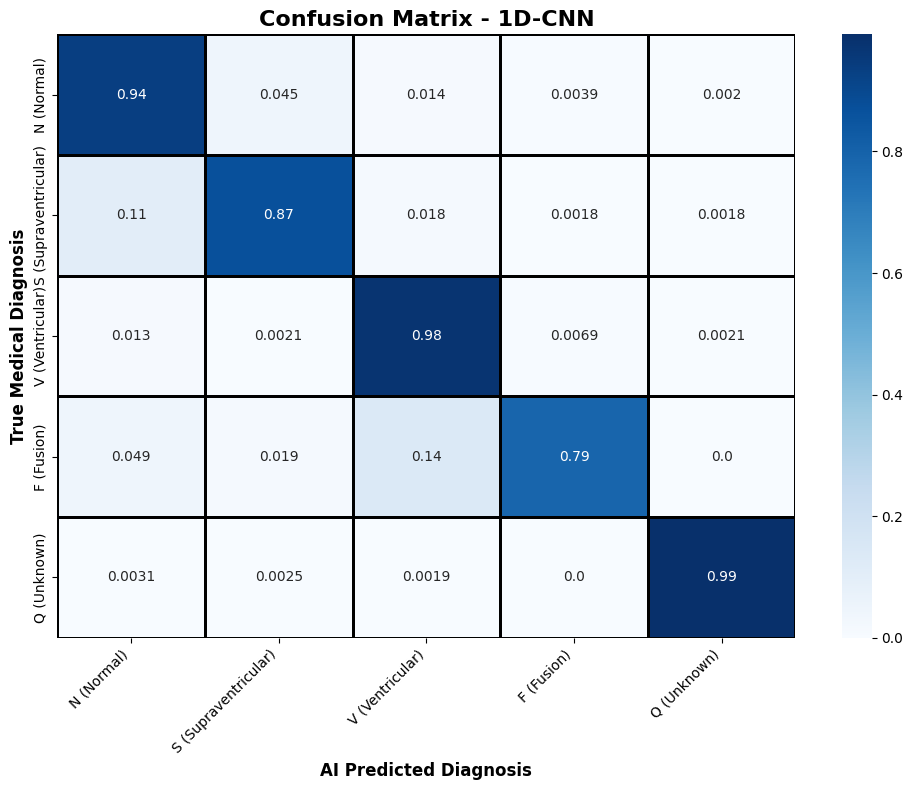

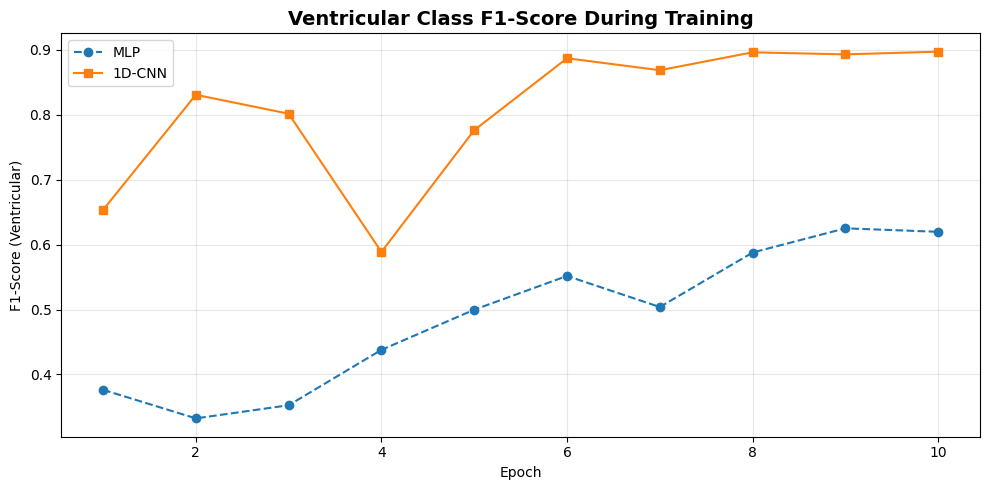


Model Comparison — Ventricular Class (Class 2):
        V Precision  V Recall  V F1-Score  Overall Accuracy
Model                                                      
MLP          0.4580    0.9572      0.6196            0.8034
1D-CNN       0.8297    0.9758      0.8969            0.9395


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score

# classification report
print("Classification Report (1D-CNN):")
print("-" * 55)
print(classification_report(cnn_all_targets, cnn_all_preds, target_names=list(class_names.values()), zero_division=0))
print("-" * 55)

# confusion matrix
cm_cnn = confusion_matrix(cnn_all_targets, cnn_all_preds)
cm_cnn_norm = cm_cnn.astype(float) / cm_cnn.sum(axis=1, keepdims=True)


plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn_norm, annot=True, fmt='.2', cmap='Blues',
            xticklabels=list(class_names.values()),
            yticklabels=list(class_names.values()),
            linewidths=1, linecolor='black')
plt.title('Confusion Matrix - 1D-CNN', fontsize=16, fontweight='bold')
plt.ylabel('True Medical Diagnosis', fontsize=12, fontweight='bold')
plt.xlabel('AI Predicted Diagnosis', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("cnn_confusion_matrix.png", dpi=300)
plt.show()

# F1 training curves
plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS+1), history_val_f1_class2, label='MLP', marker='o', linestyle='--')
plt.plot(range(1, EPOCHS+1), cnn_history_val_f1_class2, label='1D-CNN', marker='s')
plt.title('Ventricular Class F1-Score During Training', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('F1-Score (Ventricular)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("mlp_vs_cnn_f1_curve.png", dpi=300)
plt.show()

# comparison table
from sklearn.metrics import precision_score, recall_score

def ventricular_metrics(targets, preds):
    p = precision_score(targets, preds, average=None, zero_division=0)[2]
    r = recall_score(targets, preds, average=None, zero_division=0)[2]
    f = f1_score(targets, preds, average=None, zero_division=0)[2]
    acc = (np.array(targets) == np.array(preds)).mean()
    return p, r, f, acc

mlp_p, mlp_r, mlp_f, mlp_acc = ventricular_metrics(mlp_all_targets, mlp_all_preds)
cnn_p, cnn_r, cnn_f, cnn_acc = ventricular_metrics(cnn_all_targets, cnn_all_preds)
comparison_df = pd.DataFrame({
    'Model':               ['MLP',    '1D-CNN'],
    'V Precision':         [mlp_p,    cnn_p],
    'V Recall':            [mlp_r,    cnn_r],
    'V F1-Score':          [mlp_f,    cnn_f],
    'Overall Accuracy':    [mlp_acc,  cnn_acc],
}).set_index('Model').round(4)

print("\nModel Comparison — Ventricular Class (Class 2):")
print(comparison_df.to_string())

## 14. CNN Analysis and Model Comparison

When comparing the MLP and the 1D-CNN side by side, it becomes pretty clear that learning spatial features makes a real difference for ECG classification.

Both models handle Sensitivity well. Since we used cost-sensitive learning with custom class weights, both architectures ended up hitting our main clinical goal: catching almost all Ventricular beats. The MLP got 95.72% of them, and the CNN got 97.58%. Either way, our design choices let to the desired results.

Where the CNN pulls ahead is Precision. The MLP only managed a Precision of 0.45, meaning it is generating a ton of false alarms. Flattening the heartbeat into a 1D vector and feeding raw amplitudes into the network means the MLP struggles to understand the continuous "shape" of the wave, just individual values.

The 1D-CNN handles this differently. Its sliding convolutional filters are actually picking up on local patterns, e.g. things like how wide the QRS complex is, or whether a T-wave is inverted. That awareness of waveform morphology is what let it cut false positives dramatically and push Precision up to 0.83, almost double the MLP's.

Bottom line: The CNN kept recall high while massively improving Precision, landing an F1-Score of 0.90 on the Ventricular class versus the MLP's 0.62, with an overall accuracy of 0.9395. For clinical heartbeat classification, the 1D-CNN is the obvious choice, it is safe and reliable.

## 15. Saliency Map

A saliency map is a way of visualizing what the model was actually "paying attention to" when it made a prediction.
The process is fairly straightforward: we pass a sample through the model, backpropagate the Ventricular class score back to the input layer, and look at the absolute gradient values. Wherever the gradient is large, that part of the signal had more influence on the final prediction.
We ran this on the same Ventricular beat for both models. If the CNN has genuinely learned ECG morphology, we would expect it to focus around the QRS complex (the spike of the wave). The MLP, since it has no sense of local structure, tends to spread its attention all over the place and produce a much noisier saliency pattern.

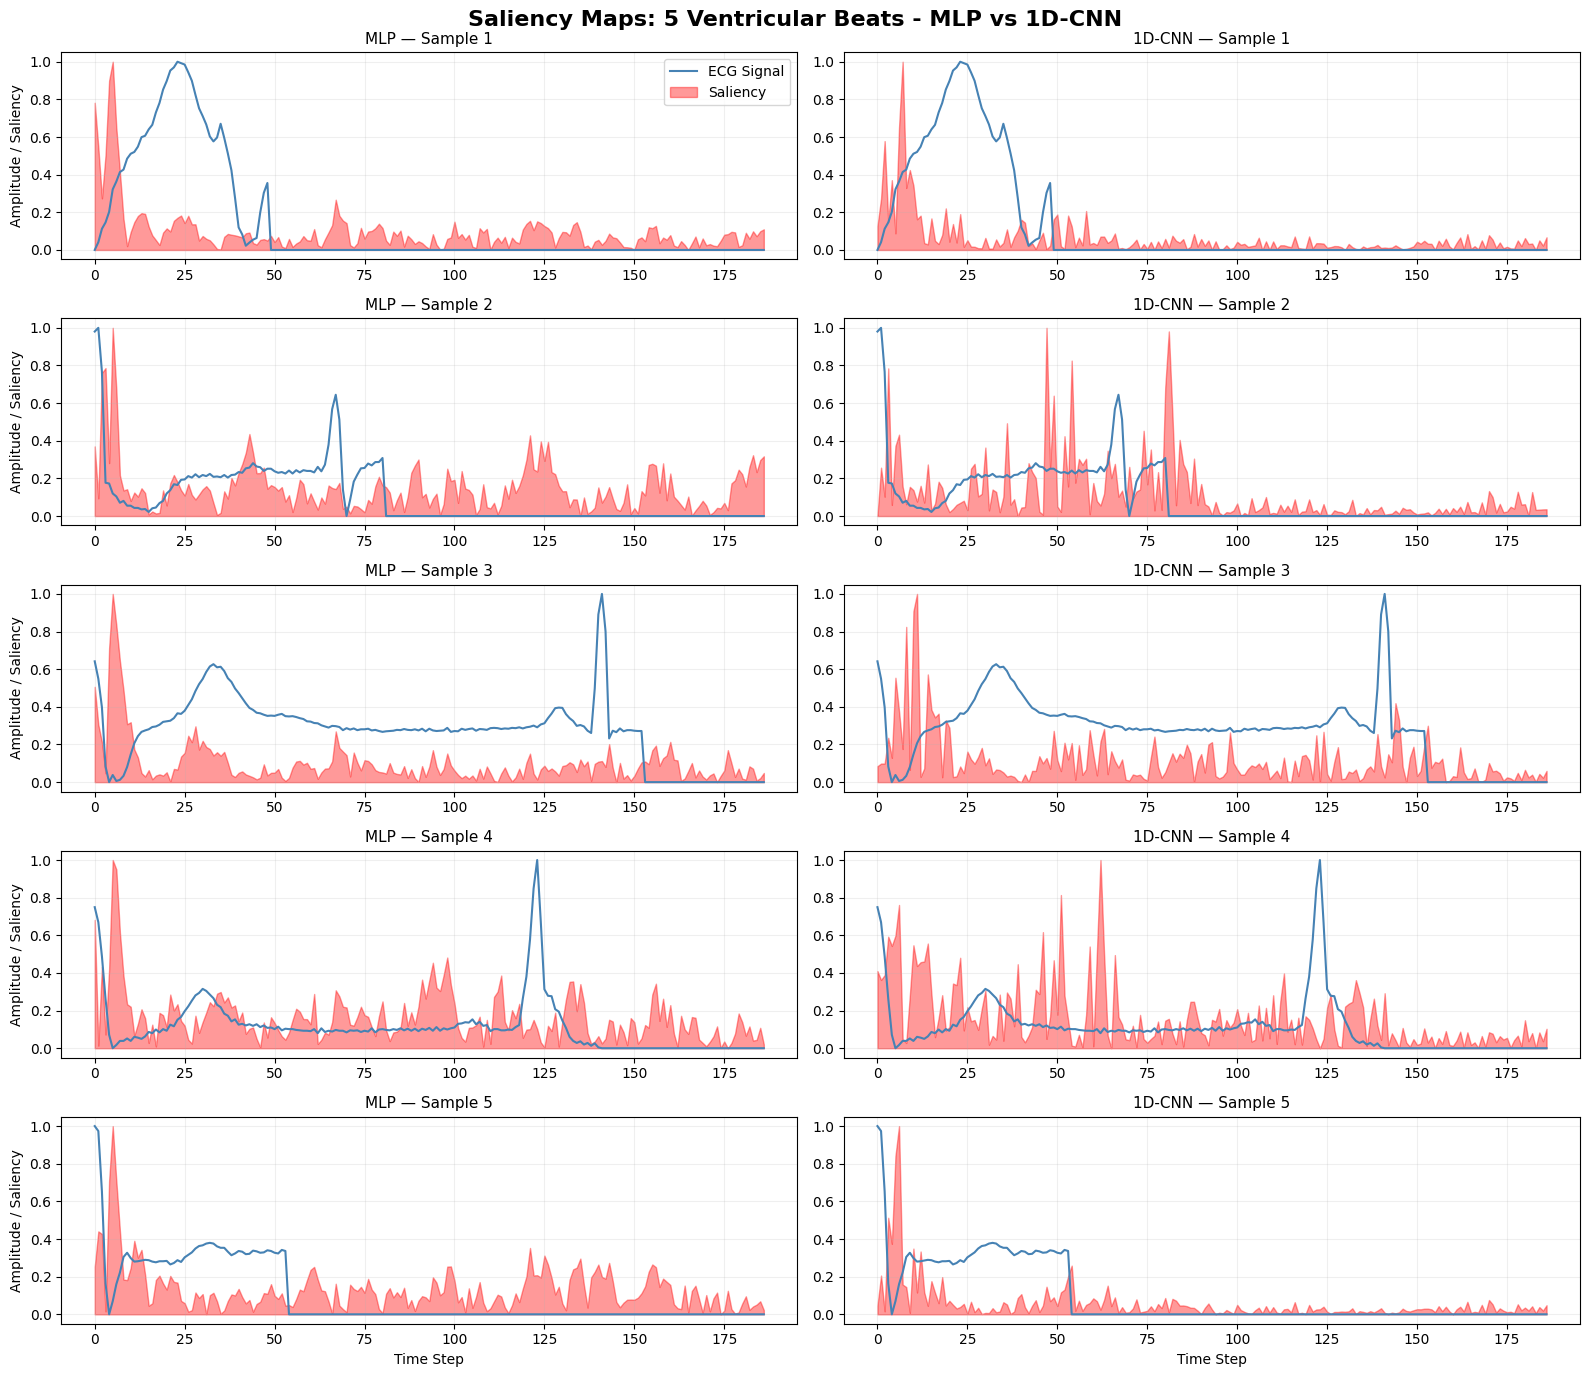

In [ ]:
def compute_saliency(model, x_input):
    model.eval()
    x = x_input.clone().detach().unsqueeze(0).to(device)
    x.requires_grad_(True)
    x.retain_grad()

    output = model(x)
    score = output[0, 2]
    score.backward()

    if x.grad is None:
        print(f"WARNING: x.grad is None for {model.__class__.__name__}")
        return np.zeros(187)

    saliency = x.grad.abs().squeeze().cpu().numpy()
    return saliency

# Pick correctly predicted Ventricular samples
cnn_model.eval()
sample_signals, saliency_mlp, saliency_cnn = [], [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        mask = y_batch == 2
        if mask.any():
            idx = mask.nonzero(as_tuple=True)[0][0]
            sample_signals.append(X_batch[idx])
            if len(sample_signals) == 5:
                break


# Compute saliency
for signal in sample_signals:
  saliency_mlp.append(compute_saliency(mlp_model, signal))
  saliency_cnn.append(compute_saliency(cnn_model, signal))

# Plot
fig, axes = plt.subplots(5, 2, figsize=(16, 14))
fig.suptitle('Saliency Maps: 5 Ventricular Beats - MLP vs 1D-CNN',
             fontsize=16, fontweight='bold')

time_steps = range(187)

for row in range(5):
    ecg = sample_signals[row].numpy()

    for col, (saliency, title) in enumerate([
        (saliency_mlp[row], 'MLP'),
        (saliency_cnn[row], '1D-CNN')
    ]):
        ax = axes[row, col]

        # Normalize saliency to [0, 1] for the color fill
        sal_norm = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

        ax.plot(time_steps, ecg, color='steelblue', linewidth=1.5, label='ECG Signal')
        ax.fill_between(time_steps, 0, sal_norm, alpha=0.4, color='red', label='Saliency')
        ax.set_title(f'{title} — Sample {row+1}', fontsize=11)

        if row == 4:
            ax.set_xlabel('Time Step')
        if col == 0:
            ax.set_ylabel('Amplitude / Saliency')
        if row == 0 and col == 0:
            ax.legend(loc='upper right')
        ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig("saliency_map_5_samples.png", dpi=300, bbox_inches='tight')
plt.show()

## 16. Final Project Conclusion and Saliency Analysis

The goal of this project was never to maximize overall accuracy, it was to build a screening system that does not miss dangerous, life-threatening heartbeats. On that front, both models delivered. The cost-sensitive weighting on the Ventricular class was the single most impactful design decision, and it succeeded in pushing Recall to near-perfect levels.

The CNN outperformed the MLP on the Ventricular F1-Score, perfectly illustrating the advantage of spatial feature extraction. By learning to detect the actual shape (morphology) of the wave rather than just correlating raw amplitudes, the CNN produced far fewer false alarms without sacrificing the high Recall the MLP already had.

**Interpretability (Saliency Maps):**
The generated saliency maps back this up visually. By backpropagating the Ventricular class score to the input, we can see exactly what drove the models' predictions. In the sample plot of Sample 1, the abnormal QRS complex occurs between time steps 0 and 50. While both models correctly focus heavy attention on this region, the MLP's attention is noisy and scattered, with significant false importance placed on the flat resting phase (steps 50–180). Contrarily, it is very noticeable how the CNN ignores the empty signal after the beat.

**Clinical Trade-offs:**
The main trade-off throughout this project was Precision vs. Recall. The clinical weight multiplier was manually set to 5.0, which deliberately pushed both models toward over-sensitivity on ventricular beats. In a real clinical setting, this threshold would need to be carefully validated by medical professionals. While catching every dangerous beat is paramount, too many false alarms cause "alarm fatigue," which poses its own unique risk to patient safety.

## 17. Demo: Real-Time Inference [Extra]

To demonstrate how this model would function in a clinical deployment, we will save the trained 1D-CNN parameters to disk. This simulates preparing the model for deployment.

Next, we simulate a real-time patient monitoring scenario. We will pass unseen heartbeat signals into the model one by one and plot the raw ECG waveform alongside the model's predicted diagnosis versus the true diagnosis.

Model successfully saved to best_1d_cnn_ecg.pth



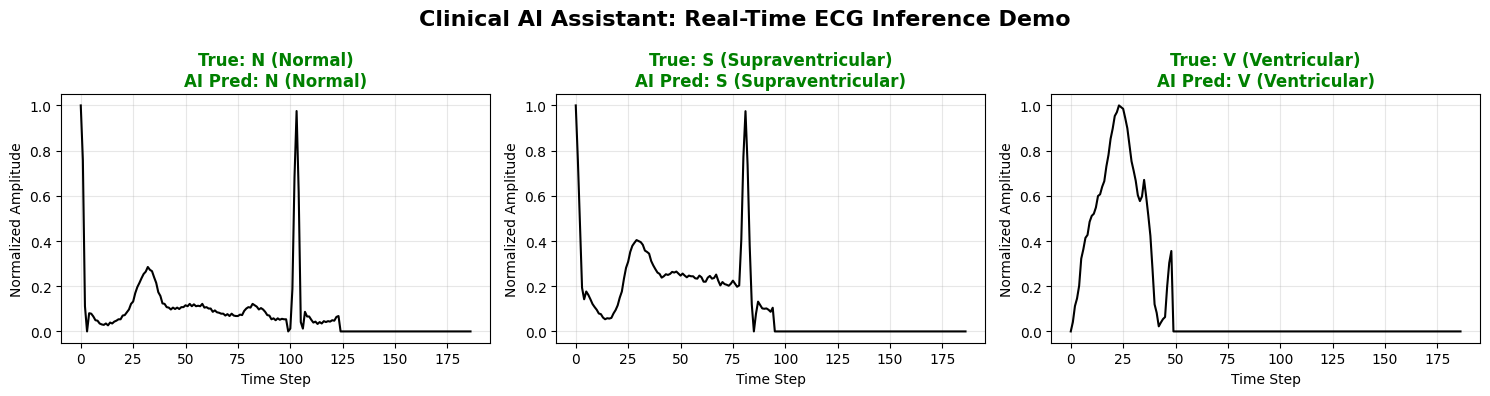

In [ ]:
# Save the trained 1D-CNN model weights
model_save_path = "best_1d_cnn_ecg.pth"
torch.save(cnn_model.state_dict(), model_save_path)
print(f"Model successfully saved to {model_save_path}\n")

# Select specific classes to demo: Normal (0), Supraventricular (1), Ventricular (2)
demo_classes = [0, 1, 2]
demo_samples = []
demo_labels = []

# Hunt through the test set to find one example of each
cnn_model.eval()
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        for i in range(len(y_batch)):
            true_class = y_batch[i].item()
            if true_class in demo_classes:
                demo_samples.append(X_batch[i])
                demo_labels.append(true_class)
                demo_classes.remove(true_class) # Remove from list so we only grab one
            if not demo_classes:
                break
        if not demo_classes:
            break

# Run Inference and Plot the Results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Clinical AI Assistant: Real-Time ECG Inference Demo', fontsize=16, fontweight='bold')

time_steps = range(187)

for i in range(3):
    # Add the batch dimension back so PyTorch can process a single sample, and send to device
    sample = demo_samples[i].unsqueeze(0).to(device)
    true_label = demo_labels[i]

    # The AI makes its prediction
    output = cnn_model(sample)
    predicted_class = torch.argmax(output, dim=1).item()

    # Map the numeric indices back to our readable medical names
    true_name = list(class_names.values())[true_label]
    pred_name = list(class_names.values())[predicted_class]

    # Color coding the title
    title_color = 'green' if true_label == predicted_class else 'red'

    # Plot the waveform
    ax = axes[i]
    ax.plot(time_steps, demo_samples[i].cpu().squeeze().numpy(), color='black', linewidth=1.5)
    ax.set_title(f"True: {true_name}\nAI Pred: {pred_name}", color=title_color, fontsize=12, fontweight='bold')
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Normalized Amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("inference_demo.png", dpi=300)
plt.show()